# Data Science Capstone Project: Customer Churn Prediction
This notebook covers data generation/loading, data cleaning, exploratory data analysis (EDA), and machine learning model evaluation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Load or Generate Dataset
np.random.seed(42)
n_samples = 1000

data = {
    'CustomerID': [f'CUST_{i:04d}' for i in range(1, n_samples + 1)],
    'Tenure_Months': np.random.randint(1, 72, n_samples),
    'Monthly_Charges': np.round(np.random.uniform(20.0, 120.0, n_samples), 2),
    'Contract_Type': np.random.choice(['Month-to-Month', 'One Year', 'Two Year'], n_samples, p=[0.5, 0.3, 0.2]),
    'Tech_Support': np.random.choice(['Yes', 'No'], n_samples, p=[0.4, 0.6]),
    'Payment_Method': np.random.choice(['Electronic Check', 'Credit Card', 'Bank Transfer'], n_samples)
}

df = pd.DataFrame(data)
df['Total_Charges'] = np.round(df['Tenure_Months'] * df['Monthly_Charges'], 2)

churn_prob = (
    (df['Contract_Type'] == 'Month-to-Month').astype(int) * 0.35 +
    (df['Tenure_Months'] < 12).astype(int) * 0.25 +
    (df['Tech_Support'] == 'No').astype(int) * 0.15 +
    np.random.uniform(0, 0.25, n_samples)
)
df['Churn'] = np.where(churn_prob > 0.55, 'Yes', 'No')
df.to_csv('customer_churn_data.csv', index=False)
print("Dataset Shape:", df.shape)
df.head()


Dataset Shape: (1000, 8)


,CustomerID,Tenure_Months,Monthly_Charges,Contract_Type,Tech_Support,Payment_Method,Total_Charges,Churn
0,CUST_0001,52,105.57,Month-to-Month,No,Credit Card,5489.64,Yes
1,CUST_0002,15,103.02,Two Year,No,Credit Card,1545.30,No
2,CUST_0003,61,59.72,Month-to-Month,No,Electronic Check,3642.92,Yes
3,CUST_0004,21,86.81,One Year,Yes,Electronic Check,1823.01,No
4,CUST_0005,24,40.50,One Year,No,Electronic Check,972.00,No


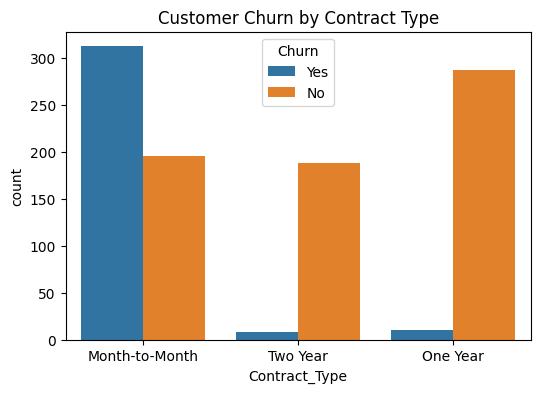

In [2]:
# 2. Data Cleaning & Label Encoding
df_clean = df.drop('CustomerID', axis=1).copy()
le = LabelEncoder()
for col in ['Contract_Type', 'Tech_Support', 'Payment_Method', 'Churn']:
    df_clean[col] = le.fit_transform(df_clean[col])

# 3. Exploratory Data Analysis Visuals
plt.figure(figsize=(6, 4))
sns.countplot(x='Contract_Type', hue='Churn', data=df)
plt.title('Customer Churn by Contract Type')
plt.show()


In [3]:
# 4. Train-Test Split (80% Train, 20% Test)
X = df_clean.drop('Churn', axis=1)
y = df_clean['Churn']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Model Training & Performance Evaluation
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results.append({
        'Model': name,
        'Accuracy (%)': round(accuracy_score(y_test, y_pred) * 100, 2),
        'Precision (%)': round(precision_score(y_test, y_pred) * 100, 2),
        'Recall (%)': round(recall_score(y_test, y_pred) * 100, 2),
        'F1-Score (%)': round(f1_score(y_test, y_pred) * 100, 2)
    })

performance_df = pd.DataFrame(results)
print(performance_df.to_string(index=False))


              Model  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)
Logistic Regression          87.0          83.82       79.17         81.43
      Decision Tree          90.5          87.32       86.11         86.71
      Random Forest          89.0          87.88       80.56         84.06
